In [1]:
# ============================================================
# NOTEBOOK 5: FAISS VECTOR DATABASE
# ============================================================
# Project:
# Healthcare Retrieval-Augmented Generation (RAG) System
#
# Purpose:
# Build separate FAISS vector indexes for the four embedding
# models evaluated in the dissertation.
#
# Embedding Models:
#   1. MiniLM
#   2. MPNet
#   3. E5
#   4. BGE
#
# Each model has:
#   - 3,796 NHS document embeddings
#   - Its own embedding dimension
#   - Its own FAISS index
#
# The indexes will later be used for semantic retrieval.
# ============================================================


# ============================================================
# STEP 1: MOUNT GOOGLE DRIVE
# ============================================================
# The embedding files generated in Notebook 4 are stored in
# the Healthcare_RAG project directory on Google Drive.
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# ============================================================
# STEP 2: INSTALL REQUIRED FAISS LIBRARY
# ============================================================
# FAISS (Facebook AI Similarity Search) is used to create a
# searchable vector index from our NHS document embeddings.
#
# We will use FAISS to perform fast semantic similarity
# searches when a user asks a healthcare question.
#
# faiss-cpu is sufficient because our current knowledge base
# contains only 3,796 document chunks.
# ============================================================

!pip install -q faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 29.7 MB/s eta 0:00:00


In [3]:
# ============================================================
# STEP 3: IMPORT REQUIRED LIBRARIES
# ============================================================
# Path:
#   Used to manage project directories and file paths.
#
# JSON:
#   Used to load the embedding datasets generated in Notebook 4.
#
# NumPy:
#   Converts the embedding lists into numerical matrices that
#   FAISS can process.
#
# FAISS:
#   Creates and searches the vector indexes.
#
# Time:
#   Used to measure FAISS index-building time for our
#   experimental/reporting results.
# ============================================================

from pathlib import Path
import json
import time

import numpy as np
import faiss

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [4]:
# ============================================================
# STEP 4: DEFINE PROJECT PATHS
# ============================================================
# Input:
#   data/embeddings/
#       MiniLM/all_embeddings.json
#       MPNet/all_embeddings.json
#       E5/all_embeddings.json
#       BGE/all_embeddings.json
#
# Output:
#   data/faiss/
#       MiniLM/
#       MPNet/
#       E5/
#       BGE/
#
# Each model will receive its own FAISS index and metadata.
# ============================================================

# Main project directory
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Healthcare_RAG"
)

# Directory containing the four embedding datasets
EMBEDDING_DIR = PROJECT_DIR / "data" / "embeddings"

# Directory where FAISS indexes will be stored
FAISS_DIR = PROJECT_DIR / "data" / "faiss"

# Create FAISS output directory
FAISS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Models used in the experiment
MODEL_NAMES = [
    "MiniLM",
    "MPNet",
    "E5",
    "BGE"
]

# Display paths
print("=" * 70)
print("PROJECT PATHS")
print("=" * 70)

print(f"Project Directory : {PROJECT_DIR}")
print(f"Embedding Folder  : {EMBEDDING_DIR}")
print(f"FAISS Folder      : {FAISS_DIR}")

print("\nModels:")
for model in MODEL_NAMES:
    print(f"  - {model}")

print("=" * 70)

PROJECT PATHS
Project Directory : /content/drive/MyDrive/Healthcare_RAG
Embedding Folder  : /content/drive/MyDrive/Healthcare_RAG/data/embeddings
FAISS Folder      : /content/drive/MyDrive/Healthcare_RAG/data/faiss

Models:
  - MiniLM
  - MPNet
  - E5
  - BGE


In [5]:
# ============================================================
# STEP 5: LOAD AND INSPECT EMBEDDING DATASETS
# ============================================================
# This cell:
#   1. Locates the embedding JSON file for each model.
#   2. Loads the data.
#   3. Checks the number of embeddings.
#   4. Checks the embedding dimension.
#
# We do this BEFORE building FAISS indexes so that any
# missing/corrupted embedding dataset is detected early.
# ============================================================

embedding_data = {}

print("=" * 70)
print("CHECKING EMBEDDING DATASETS")
print("=" * 70)

for model_name in MODEL_NAMES:

    # --------------------------------------------------------
    # Locate the model's embedding file
    # --------------------------------------------------------

    embedding_file = (
        EMBEDDING_DIR
        / model_name
        / "all_embeddings.json"
    )

    print("\n" + "-" * 70)
    print(f"MODEL: {model_name}")

    # --------------------------------------------------------
    # Check that the file exists
    # --------------------------------------------------------

    if not embedding_file.exists():

        raise FileNotFoundError(
            f"Embedding file not found: {embedding_file}"
        )

    # --------------------------------------------------------
    # Load embedding data
    # --------------------------------------------------------

    with open(
        embedding_file,
        "r",
        encoding="utf-8"
    ) as file:

        data = json.load(file)

    # Store the loaded data
    embedding_data[model_name] = data

    # --------------------------------------------------------
    # Inspect dimensions
    # --------------------------------------------------------

    number_of_embeddings = len(data)

    embedding_dimension = len(
        data[0]["embedding"]
    )

    print(f"File Exists          : True")
    print(f"Number of Embeddings : {number_of_embeddings}")
    print(f"Embedding Dimension  : {embedding_dimension}")

print("\n")
print("=" * 70)
print("ALL EMBEDDING DATASETS LOADED SUCCESSFULLY")
print("=" * 70)

CHECKING EMBEDDING DATASETS

----------------------------------------------------------------------
MODEL: MiniLM
File Exists          : True
Number of Embeddings : 3796
Embedding Dimension  : 384

----------------------------------------------------------------------
MODEL: MPNet
File Exists          : True
Number of Embeddings : 3796
Embedding Dimension  : 768

----------------------------------------------------------------------
MODEL: E5
File Exists          : True
Number of Embeddings : 3796
Embedding Dimension  : 768

----------------------------------------------------------------------
MODEL: BGE
File Exists          : True
Number of Embeddings : 3796
Embedding Dimension  : 384


ALL EMBEDDING DATASETS LOADED SUCCESSFULLY


In [6]:
# ============================================================
# STEP 6: BUILD FAISS INDEXES FOR ALL FOUR MODELS
# ============================================================
# This cell:
#   1. Extracts the embeddings for each model.
#   2. Converts them to NumPy float32 matrices.
#   3. Creates a FAISS IndexFlatIP index.
#   4. Adds all NHS document vectors to the index.
#   5. Saves each index to Google Drive.
#
# Why IndexFlatIP?
#   Our embeddings were normalized in Notebook 4.
#   Therefore:
#
#       Inner Product = Cosine Similarity
#
#   This matches the cosine-similarity retrieval approach
#   specified in the project methodology.
# ============================================================

# Dictionary to store FAISS indexes in memory
faiss_indexes = {}

# Dictionary to store index-building statistics
faiss_build_results = []

print("=" * 70)
print("BUILDING FAISS INDEXES")
print("=" * 70)

# ------------------------------------------------------------
# Process each embedding model
# ------------------------------------------------------------

for model_name in MODEL_NAMES:

    print("\n" + "=" * 70)
    print(f"BUILDING INDEX: {model_name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Get embedding records
    # --------------------------------------------------------

    data = embedding_data[model_name]

    # --------------------------------------------------------
    # Convert embedding lists into a NumPy matrix
    # --------------------------------------------------------

    vectors = np.asarray(
        [item["embedding"] for item in data],
        dtype=np.float32
    )

    print(f"Vector Matrix Shape : {vectors.shape}")

    # --------------------------------------------------------
    # Determine vector dimension
    # --------------------------------------------------------

    dimension = vectors.shape[1]

    # --------------------------------------------------------
    # Create exact FAISS Inner Product index
    # --------------------------------------------------------

    index = faiss.IndexFlatIP(dimension)

    # --------------------------------------------------------
    # Measure indexing time
    # --------------------------------------------------------

    start_time = time.time()

    # Add all vectors to FAISS
    index.add(vectors)

    build_time = time.time() - start_time

    # --------------------------------------------------------
    # Store index in memory
    # --------------------------------------------------------

    faiss_indexes[model_name] = index

    # --------------------------------------------------------
    # Create model-specific FAISS directory
    # --------------------------------------------------------

    model_faiss_dir = FAISS_DIR / model_name

    model_faiss_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # --------------------------------------------------------
    # Save FAISS index
    # --------------------------------------------------------

    index_path = (
        model_faiss_dir /
        "faiss_index.bin"
    )

    faiss.write_index(
        index,
        str(index_path)
    )

    # --------------------------------------------------------
    # Store experimental statistics
    # --------------------------------------------------------

    faiss_build_results.append({

        "Model": model_name,

        "Vectors": index.ntotal,

        "Dimension": dimension,

        "Build_Time_Seconds": round(
            build_time,
            4
        ),

        "Index_File": str(index_path)

    })

    print(f"Vectors Indexed : {index.ntotal}")
    print(f"Dimension       : {dimension}")
    print(f"Build Time      : {build_time:.4f} seconds")
    print(f"Saved To        : {index_path}")


# ------------------------------------------------------------
# Final message
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("ALL FAISS INDEXES CREATED SUCCESSFULLY")
print("=" * 70)

for model_name, index in faiss_indexes.items():

    print(
        f"{model_name:8} → "
        f"{index.ntotal} vectors"
    )

print("=" * 70)

BUILDING FAISS INDEXES

BUILDING INDEX: MiniLM
Vector Matrix Shape : (3796, 384)
Vectors Indexed : 3796
Dimension       : 384
Build Time      : 0.0049 seconds
Saved To        : /content/drive/MyDrive/Healthcare_RAG/data/faiss/MiniLM/faiss_index.bin

BUILDING INDEX: MPNet
Vector Matrix Shape : (3796, 768)
Vectors Indexed : 3796
Dimension       : 768
Build Time      : 0.0054 seconds
Saved To        : /content/drive/MyDrive/Healthcare_RAG/data/faiss/MPNet/faiss_index.bin

BUILDING INDEX: E5
Vector Matrix Shape : (3796, 768)
Vectors Indexed : 3796
Dimension       : 768
Build Time      : 0.0071 seconds
Saved To        : /content/drive/MyDrive/Healthcare_RAG/data/faiss/E5/faiss_index.bin

BUILDING INDEX: BGE
Vector Matrix Shape : (3796, 384)
Vectors Indexed : 3796
Dimension       : 384
Build Time      : 0.0029 seconds
Saved To        : /content/drive/MyDrive/Healthcare_RAG/data/faiss/BGE/faiss_index.bin


ALL FAISS INDEXES CREATED SUCCESSFULLY
MiniLM   → 3796 vectors
MPNet    → 3796 vectors


In [7]:
# ============================================================
# STEP 7: CREATE METADATA FILES FOR ALL FOUR MODELS
# ============================================================
# This cell:
#   1. Extracts the metadata from each embedding dataset.
#   2. Removes the large embedding vectors.
#   3. Preserves the original NHS text and source information.
#   4. Saves one metadata file alongside each FAISS index.
#
# IMPORTANT:
# The order is NOT changed.
#
# Therefore:
#
#   FAISS vector ID 0  <-->  metadata record 0
#   FAISS vector ID 1  <-->  metadata record 1
#   FAISS vector ID 2  <-->  metadata record 2
#   ...
#
# This mapping will later allow the RAG pipeline to retrieve
# the actual NHS text after FAISS finds the nearest vectors.
# ============================================================

metadata_files = {}

print("=" * 70)
print("CREATING FAISS METADATA FILES")
print("=" * 70)

# ------------------------------------------------------------
# Process each embedding model
# ------------------------------------------------------------

for model_name in MODEL_NAMES:

    print("\n" + "-" * 70)
    print(f"CREATING METADATA: {model_name}")
    print("-" * 70)

    # Get the embedding records
    data = embedding_data[model_name]

    # --------------------------------------------------------
    # Create metadata records
    # --------------------------------------------------------

    metadata = []

    for item in data:

        metadata.append({

            # Original NHS chunk identifier
            "chunk_id": item["chunk_id"],

            # Original NHS article
            "source_file": item["source_file"],

            # Length of the original chunk
            "chunk_length": item["chunk_length"],

            # Original NHS text
            "text": item["text"]

        })

    # --------------------------------------------------------
    # Define model-specific output directory
    # --------------------------------------------------------

    model_faiss_dir = FAISS_DIR / model_name

    model_faiss_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # --------------------------------------------------------
    # Define metadata output file
    # --------------------------------------------------------

    metadata_path = (
        model_faiss_dir /
        "metadata.json"
    )

    # --------------------------------------------------------
    # Save metadata
    # --------------------------------------------------------

    with open(
        metadata_path,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            metadata,
            file,
            ensure_ascii=False,
            indent=4
        )

    # Store path for later use
    metadata_files[model_name] = metadata_path

    print(f"Metadata Records : {len(metadata)}")
    print(f"Saved To         : {metadata_path}")


print("\n")
print("=" * 70)
print("ALL METADATA FILES CREATED SUCCESSFULLY")
print("=" * 70)

for model_name, path in metadata_files.items():

    print(f"{model_name:8} → {path}")

print("=" * 70)

CREATING FAISS METADATA FILES

----------------------------------------------------------------------
CREATING METADATA: MiniLM
----------------------------------------------------------------------
Metadata Records : 3796
Saved To         : /content/drive/MyDrive/Healthcare_RAG/data/faiss/MiniLM/metadata.json

----------------------------------------------------------------------
CREATING METADATA: MPNet
----------------------------------------------------------------------
Metadata Records : 3796
Saved To         : /content/drive/MyDrive/Healthcare_RAG/data/faiss/MPNet/metadata.json

----------------------------------------------------------------------
CREATING METADATA: E5
----------------------------------------------------------------------
Metadata Records : 3796
Saved To         : /content/drive/MyDrive/Healthcare_RAG/data/faiss/E5/metadata.json

----------------------------------------------------------------------
CREATING METADATA: BGE
---------------------------------------

In [ ]:
# ============================================================
# STEP 8: VALIDATE METADATA
# ============================================================
# This cell loads the metadata file and displays one sample
# record for verification.
# ============================================================

with open(metadata_path, "r", encoding="utf-8") as file:
    metadata_data = json.load(file)

print("=" * 70)
print("METADATA SUMMARY")
print("=" * 70)

print(f"Total Records : {len(metadata_data)}")

sample = metadata_data[0]

print("\nSample Metadata\n")

print(f"Chunk ID     : {sample['chunk_id']}")
print(f"Source File  : {sample['source_file']}")
print(f"Chunk Length : {sample['chunk_length']}")

print("\nChunk Preview:\n")

print(sample["text"][:500])

print("=" * 70)

METADATA SUMMARY
Total Records : 3796

Sample Metadata

Chunk ID     : 1
Source File  : aciclovir_zovirax.txt
Chunk Length : 456

Chunk Preview:

# Aciclovir (Zovirax)

Aciclovir is an antiviral medicine used to treat certain infections. Most types are only available with a prescription, but you can buy some types from shops and pharmacies.

## What aciclovir is for

Aciclovir is used to treat infections such as:

• cold sores

• shingles

• chickenpox

• genital herpes

• herpes simplex eye infections

It's also sometimes used to prevent these infections in people with a weakened immune system.


In [9]:
# ============================================================
# STEP 8: VALIDATE ALL FAISS INDEXES
# ============================================================
# This cell verifies:
#   1. Every FAISS index exists.
#   2. Every index contains 3,796 vectors.
#   3. Each index has the correct dimensionality.
#   4. The corresponding metadata file exists.
#   5. FAISS vector count matches metadata record count.
#
# This is an important integrity check because later retrieval
# depends on the vector ID and metadata position remaining aligned.
# ============================================================

# Expected dimensions for each embedding model
expected_dimensions = {
    "MiniLM": 384,
    "MPNet": 768,
    "E5": 768,
    "BGE": 384
}

expected_vectors = 3796

all_checks_passed = True

print("=" * 70)
print("VALIDATING FAISS INDEXES")
print("=" * 70)

# ------------------------------------------------------------
# Check every model
# ------------------------------------------------------------

for model_name in MODEL_NAMES:

    print("\n" + "-" * 70)
    print(f"CHECKING: {model_name}")
    print("-" * 70)

    # --------------------------------------------------------
    # File paths
    # --------------------------------------------------------

    model_faiss_dir = FAISS_DIR / model_name

    index_path = (
        model_faiss_dir /
        "faiss_index.bin"
    )

    metadata_path = (
        model_faiss_dir /
        "metadata.json"
    )

    # --------------------------------------------------------
    # Check FAISS index file
    # --------------------------------------------------------

    if not index_path.exists():

        print(" FAISS index not found")

        all_checks_passed = False

        continue

    print("FAISS Index Exists : True")

    # --------------------------------------------------------
    # Load FAISS index
    # --------------------------------------------------------

    index = faiss.read_index(
        str(index_path)
    )

    # --------------------------------------------------------
    # Check vector count
    # --------------------------------------------------------

    print(f"Vectors Indexed    : {index.ntotal}")
    print(f"Expected Vectors   : {expected_vectors}")

    if index.ntotal == expected_vectors:

        print("Vector Count       :  Correct")

    else:

        print("Vector Count       :  Incorrect")

        all_checks_passed = False

    # --------------------------------------------------------
    # Check embedding dimension
    # --------------------------------------------------------

    print(f"Index Dimension    : {index.d}")
    print(
        f"Expected Dimension : "
        f"{expected_dimensions[model_name]}"
    )

    if index.d == expected_dimensions[model_name]:

        print("Dimension          :  Correct")

    else:

        print("Dimension          :  Incorrect")

        all_checks_passed = False

    # --------------------------------------------------------
    # Check metadata file
    # --------------------------------------------------------

    if not metadata_path.exists():

        print("Metadata Exists    : False")

        all_checks_passed = False

        continue

    print("Metadata Exists    : True")

    # --------------------------------------------------------
    # Load metadata
    # --------------------------------------------------------

    with open(
        metadata_path,
        "r",
        encoding="utf-8"
    ) as file:

        metadata = json.load(file)

    # --------------------------------------------------------
    # Compare metadata count with FAISS vectors
    # --------------------------------------------------------

    print(f"Metadata Records   : {len(metadata)}")

    if len(metadata) == index.ntotal:

        print("Metadata Alignment :  Correct")

    else:

        print("Metadata Alignment :  Incorrect")

        all_checks_passed = False


# ------------------------------------------------------------
# Final result
# ------------------------------------------------------------

print("\n")
print("=" * 70)

if all_checks_passed:

    print(" ALL FAISS VALIDATION CHECKS PASSED")
    print("=" * 70)
    print("All four indexes are ready for retrieval experiments.")

else:

    print(" FAISS VALIDATION FAILED")
    print("=" * 70)
    print("Check the errors above before continuing.")

print("=" * 70)

VALIDATING FAISS INDEXES

----------------------------------------------------------------------
CHECKING: MiniLM
----------------------------------------------------------------------
FAISS Index Exists : True
Vectors Indexed    : 3796
Expected Vectors   : 3796
Vector Count       :  Correct
Index Dimension    : 384
Expected Dimension : 384
Dimension          :  Correct
Metadata Exists    : True
Metadata Records   : 3796
Metadata Alignment :  Correct

----------------------------------------------------------------------
CHECKING: MPNet
----------------------------------------------------------------------
FAISS Index Exists : True
Vectors Indexed    : 3796
Expected Vectors   : 3796
Vector Count       :  Correct
Index Dimension    : 768
Expected Dimension : 768
Dimension          :  Correct
Metadata Exists    : True
Metadata Records   : 3796
Metadata Alignment :  Correct

----------------------------------------------------------------------
CHECKING: E5
-------------------------------

In [10]:
# ============================================================
# STEP 9: CREATE FAISS EXPERIMENTAL SUMMARY
# ============================================================
# This cell creates a structured summary of the FAISS indexes.
#
# We record:
#   - Embedding model
#   - Number of indexed vectors
#   - Vector dimension
#   - FAISS index type
#   - Index construction time
#
# These are actual measurements from our experiment and can
# later be used in the dissertation results section.
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Convert FAISS build results into a DataFrame
# ------------------------------------------------------------

faiss_summary = pd.DataFrame(
    faiss_build_results
)

# ------------------------------------------------------------
# Add the index type used in the experiment
# ------------------------------------------------------------

faiss_summary["Index_Type"] = "IndexFlatIP"

# ------------------------------------------------------------
# Reorder columns for readability
# ------------------------------------------------------------

faiss_summary = faiss_summary[
    [
        "Model",
        "Vectors",
        "Dimension",
        "Index_Type",
        "Build_Time_Seconds",
        "Index_File"
    ]
]

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("=" * 70)
print("FAISS EXPERIMENTAL SUMMARY")
print("=" * 70)

display(faiss_summary)

print("=" * 70)

FAISS EXPERIMENTAL SUMMARY


,Model,Vectors,Dimension,Index_Type,Build_Time_Seconds,Index_File
0,MiniLM,3796,384,IndexFlatIP,0.0049,/content/drive/MyDrive/Healthcare_RAG/data/fai...
1,MPNet,3796,768,IndexFlatIP,0.0054,/content/drive/MyDrive/Healthcare_RAG/data/fai...
2,E5,3796,768,IndexFlatIP,0.0071,/content/drive/MyDrive/Healthcare_RAG/data/fai...
3,BGE,3796,384,IndexFlatIP,0.0029,/content/drive/MyDrive/Healthcare_RAG/data/fai...


FAISS RESULTS SAVED
CSV File : /content/drive/MyDrive/Healthcare_RAG/results/faiss_experimental_summary.csv


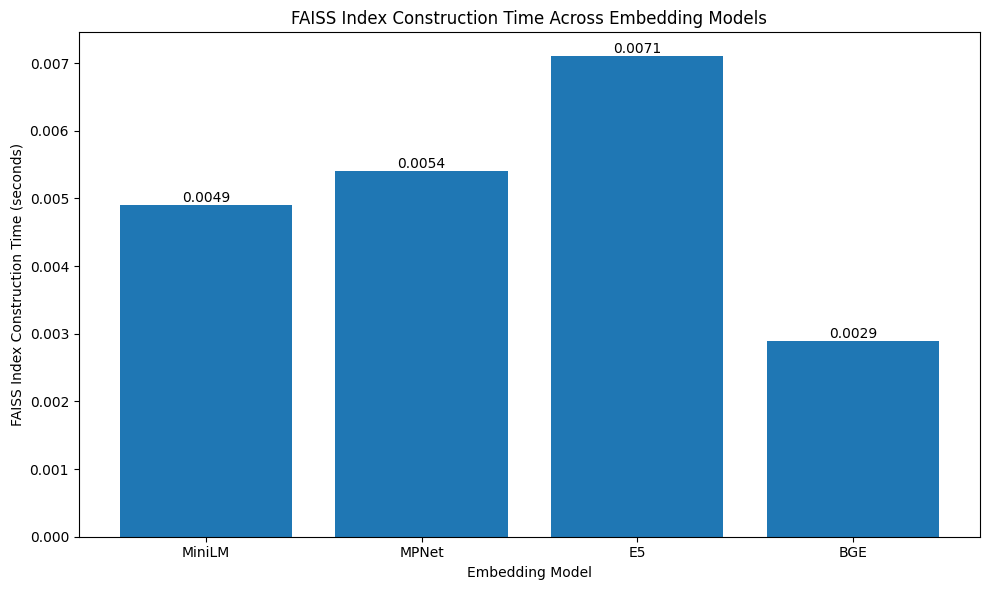



REPORT FIGURE CREATED
Figure Saved To : /content/drive/MyDrive/Healthcare_RAG/results/faiss_index_construction_time.png


In [11]:
# ============================================================
# STEP 10: SAVE FAISS RESULTS AND CREATE REPORT GRAPH
# ============================================================
# This cell:
#   1. Saves the FAISS experimental summary as CSV.
#   2. Creates a graph comparing FAISS index construction time.
#   3. Saves the graph at 300 DPI for dissertation use.
#
# IMPORTANT:
#   These values come directly from the actual experiment.
#   Nothing is manually entered or fabricated.
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Create report/output directory
# ------------------------------------------------------------

RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Save FAISS summary as CSV
# ------------------------------------------------------------

faiss_csv_path = (
    RESULTS_DIR /
    "faiss_experimental_summary.csv"
)

faiss_summary.to_csv(
    faiss_csv_path,
    index=False
)

print("=" * 70)
print("FAISS RESULTS SAVED")
print("=" * 70)

print(f"CSV File : {faiss_csv_path}")

# ------------------------------------------------------------
# Extract data for graph
# ------------------------------------------------------------

models = faiss_summary["Model"]

build_times = faiss_summary["Build_Time_Seconds"]

# ------------------------------------------------------------
# Create graph
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    models,
    build_times
)

plt.xlabel("Embedding Model")

plt.ylabel("FAISS Index Construction Time (seconds)")

plt.title(
    "FAISS Index Construction Time Across Embedding Models"
)

# ------------------------------------------------------------
# Add exact values above bars
# ------------------------------------------------------------

for i, value in enumerate(build_times):

    plt.text(
        i,
        value,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

# ------------------------------------------------------------
# Improve layout
# ------------------------------------------------------------

plt.tight_layout()

# ------------------------------------------------------------
# Save figure at dissertation quality
# ------------------------------------------------------------

faiss_graph_path = (
    RESULTS_DIR /
    "faiss_index_construction_time.png"
)

plt.savefig(
    faiss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# Display graph
# ------------------------------------------------------------

plt.show()

print("\n")
print("=" * 70)
print("REPORT FIGURE CREATED")
print("=" * 70)

print(f"Figure Saved To : {faiss_graph_path}")

print("=" * 70)

In [14]:
# ============================================================
# STEP 11: FINAL FAISS RETRIEVAL TEST
# ============================================================
# This cell is completely self-contained.
#
# It imports everything required so it does NOT depend on
# variables/imports remaining in the Colab runtime.
#
# Test question:
#   "What are the symptoms of asthma?"
#
# This is a pipeline validation test only.
# Formal Precision@K, Recall@K, MRR and nDCG evaluation
# will be performed later.
# ============================================================

# ------------------------------------------------------------
# IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

import json
import numpy as np
import faiss

from pathlib import Path
from sentence_transformers import SentenceTransformer


# ------------------------------------------------------------
# DEFINE PROJECT PATH
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Healthcare_RAG"
)

FAISS_DIR = PROJECT_DIR / "data" / "faiss"


# ------------------------------------------------------------
# DEFINE THE FOUR EMBEDDING MODELS
# ------------------------------------------------------------

EMBEDDING_MODELS = {

    "MiniLM":
        "sentence-transformers/all-MiniLM-L6-v2",

    "MPNet":
        "sentence-transformers/all-mpnet-base-v2",

    "E5":
        "intfloat/multilingual-e5-base",

    "BGE":
        "BAAI/bge-small-en-v1.5"

}


# ------------------------------------------------------------
# DEFINE MODEL ORDER
# ------------------------------------------------------------

MODEL_NAMES = [
    "MiniLM",
    "MPNet",
    "E5",
    "BGE"
]


# ------------------------------------------------------------
# DEFINE TEST QUESTION
# ------------------------------------------------------------

test_question = "What are the symptoms of asthma?"

TOP_K = 3


print("=" * 70)
print("FINAL FAISS RETRIEVAL TEST")
print("=" * 70)

print(f"Test Question : {test_question}")
print(f"Top K         : {TOP_K}")


# ============================================================
# TEST EACH MODEL
# ============================================================

for model_name in MODEL_NAMES:

    print("\n")
    print("=" * 70)
    print(f"TESTING MODEL: {model_name}")
    print("=" * 70)


    # --------------------------------------------------------
    # LOAD EMBEDDING MODEL
    # --------------------------------------------------------

    model_id = EMBEDDING_MODELS[model_name]

    print(f"Loading model: {model_id}")

    test_model = SentenceTransformer(model_id)


    # --------------------------------------------------------
    # PREPARE QUERY
    # --------------------------------------------------------
    # E5 requires "query:" for user questions.
    # Other models use the question directly.
    # --------------------------------------------------------

    if model_name == "E5":

        query_text = f"query: {test_question}"

    else:

        query_text = test_question


    # --------------------------------------------------------
    # GENERATE QUERY EMBEDDING
    # --------------------------------------------------------

    query_embedding = test_model.encode(
        [query_text],
        normalize_embeddings=True
    )

    query_embedding = np.asarray(
        query_embedding,
        dtype=np.float32
    )


    # --------------------------------------------------------
    # LOAD FAISS INDEX
    # --------------------------------------------------------

    index_path = (
        FAISS_DIR
        / model_name
        / "faiss_index.bin"
    )

    index = faiss.read_index(
        str(index_path)
    )


    # --------------------------------------------------------
    # LOAD METADATA
    # --------------------------------------------------------

    metadata_path = (
        FAISS_DIR
        / model_name
        / "metadata.json"
    )

    with open(
        metadata_path,
        "r",
        encoding="utf-8"
    ) as file:

        metadata = json.load(file)


    # --------------------------------------------------------
    # SEARCH FAISS
    # --------------------------------------------------------

    scores, indices = index.search(
        query_embedding,
        TOP_K
    )


    # --------------------------------------------------------
    # DISPLAY RESULTS
    # --------------------------------------------------------

    for rank, (score, index_id) in enumerate(
        zip(scores[0], indices[0]),
        start=1
    ):

        result = metadata[index_id]

        print("\n" + "-" * 70)

        print(f"Rank        : {rank}")
        print(f"Similarity  : {score:.4f}")
        print(f"Source File : {result['source_file']}")
        print(f"Chunk ID    : {result['chunk_id']}")

        print("\nRetrieved Text:")
        print(result["text"][:500])


print("\n")
print("=" * 70)
print("FAISS RETRIEVAL TEST COMPLETED")
print("=" * 70)

FINAL FAISS RETRIEVAL TEST
Test Question : What are the symptoms of asthma?
Top K         : 3


TESTING MODEL: MiniLM
Loading model: sentence-transformers/all-MiniLM-L6-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (48 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


----------------------------------------------------------------------
Rank        : 1
Similarity  : 0.8265
Source File : asthma.txt
Chunk ID    : 1

Retrieved Text:
# Asthma

Asthma is a common condition that affects your breathing. It cannot currently be cured, but if it's well treated you should not have problems with symptoms.

## Symptoms of asthma

The main symptoms of asthma are problems with breathing, such as:

• wheezing

• coughing

• shortness of breath

• your chest feeling tight

Asthma symptoms can be mild or severe. They usually come and go. They may be worse at night and early in the morning.

An asthma attack is when you have severe symptom

----------------------------------------------------------------------
Rank        : 2
Similarity  : 0.8027
Source File : asthma.txt
Chunk ID    : 12

Retrieved Text:
## Causes of asthma

Asthma symptoms happen when your airways become swollen. This makes them narrower, causing breathing problems.

In people who have asthma, symp

In [15]:
# ============================================================
# STEP 12: FINAL NOTEBOOK 5 VERIFICATION
# ============================================================
# This is the final integrity check for the FAISS stage.
#
# We verify for every embedding model:
#   1. FAISS index exists
#   2. Metadata file exists
#   3. FAISS contains 3,796 vectors
#   4. Metadata contains 3,796 records
#   5. Vector dimension is correct
#   6. FAISS vector count matches metadata count
#
# If every check passes, Notebook 5 is complete.
# ============================================================

import json
import faiss
from pathlib import Path


# ------------------------------------------------------------
# PROJECT PATH
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Healthcare_RAG"
)

FAISS_DIR = PROJECT_DIR / "data" / "faiss"


# ------------------------------------------------------------
# EXPECTED EXPERIMENTAL VALUES
# ------------------------------------------------------------

EXPECTED_VECTORS = 3796

EXPECTED_DIMENSIONS = {
    "MiniLM": 384,
    "MPNet": 768,
    "E5": 768,
    "BGE": 384
}

MODEL_NAMES = [
    "MiniLM",
    "MPNet",
    "E5",
    "BGE"
]


# ------------------------------------------------------------
# START VERIFICATION
# ------------------------------------------------------------

all_checks_passed = True

print("=" * 70)
print("FINAL NOTEBOOK 5 VERIFICATION")
print("=" * 70)


for model_name in MODEL_NAMES:

    print("\n" + "-" * 70)
    print(f"CHECKING: {model_name}")
    print("-" * 70)


    # --------------------------------------------------------
    # DEFINE FILE PATHS
    # --------------------------------------------------------

    model_dir = FAISS_DIR / model_name

    index_path = model_dir / "faiss_index.bin"

    metadata_path = model_dir / "metadata.json"


    # --------------------------------------------------------
    # CHECK INDEX FILE
    # --------------------------------------------------------

    if not index_path.exists():

        print("FAISS Index :  NOT FOUND")

        all_checks_passed = False

        continue

    print("FAISS Index :  Found")


    # --------------------------------------------------------
    # LOAD FAISS INDEX
    # --------------------------------------------------------

    index = faiss.read_index(
        str(index_path)
    )


    # --------------------------------------------------------
    # CHECK VECTOR COUNT
    # --------------------------------------------------------

    print(
        f"Vectors     : {index.ntotal} "
        f"(Expected: {EXPECTED_VECTORS})"
    )

    if index.ntotal == EXPECTED_VECTORS:

        print("Vector Count:  Correct")

    else:

        print("Vector Count:  Incorrect")

        all_checks_passed = False


    # --------------------------------------------------------
    # CHECK DIMENSION
    # --------------------------------------------------------

    expected_dimension = EXPECTED_DIMENSIONS[model_name]

    print(
        f"Dimension   : {index.d} "
        f"(Expected: {expected_dimension})"
    )

    if index.d == expected_dimension:

        print("Dimension   :  Correct")

    else:

        print("Dimension   :  Incorrect")

        all_checks_passed = False


    # --------------------------------------------------------
    # CHECK METADATA FILE
    # --------------------------------------------------------

    if not metadata_path.exists():

        print("Metadata    :  NOT FOUND")

        all_checks_passed = False

        continue

    print("Metadata    :  Found")


    # --------------------------------------------------------
    # LOAD METADATA
    # --------------------------------------------------------

    with open(
        metadata_path,
        "r",
        encoding="utf-8"
    ) as file:

        metadata = json.load(file)


    # --------------------------------------------------------
    # CHECK METADATA COUNT
    # --------------------------------------------------------

    print(
        f"Metadata Records: {len(metadata)} "
        f"(Expected: {EXPECTED_VECTORS})"
    )

    if len(metadata) == EXPECTED_VECTORS:

        print("Metadata Count:  Correct")

    else:

        print("Metadata Count:  Incorrect")

        all_checks_passed = False


    # --------------------------------------------------------
    # CHECK FAISS ↔ METADATA ALIGNMENT
    # --------------------------------------------------------

    if index.ntotal == len(metadata):

        print("FAISS ↔ Metadata:  Aligned")

    else:

        print("FAISS ↔ Metadata: Mismatch")

        all_checks_passed = False


# ============================================================
# FINAL RESULT
# ============================================================

print("\n")
print("=" * 70)

if all_checks_passed:

    print(" NOTEBOOK 5 COMPLETED SUCCESSFULLY")
    print("=" * 70)

    print("All four FAISS indexes are ready.")
    print("All metadata files are aligned.")
    print("The system is ready for the RAG retrieval stage.")

else:

    print(" NOTEBOOK 5 VERIFICATION FAILED")
    print("=" * 70)

    print("Fix the failed checks before continuing.")

print("=" * 70)

FINAL NOTEBOOK 5 VERIFICATION

----------------------------------------------------------------------
CHECKING: MiniLM
----------------------------------------------------------------------
FAISS Index :  Found
Vectors     : 3796 (Expected: 3796)
Vector Count:  Correct
Dimension   : 384 (Expected: 384)
Dimension   :  Correct
Metadata    :  Found
Metadata Records: 3796 (Expected: 3796)
Metadata Count:  Correct
FAISS ↔ Metadata:  Aligned

----------------------------------------------------------------------
CHECKING: MPNet
----------------------------------------------------------------------
FAISS Index :  Found
Vectors     : 3796 (Expected: 3796)
Vector Count:  Correct
Dimension   : 768 (Expected: 768)
Dimension   :  Correct
Metadata    :  Found
Metadata Records: 3796 (Expected: 3796)
Metadata Count:  Correct
FAISS ↔ Metadata:  Aligned

----------------------------------------------------------------------
CHECKING: E5
------------------------------------------------------------------

In [16]:
# ============================================================
# STEP 27: FINAL NOTEBOOK 6 VERIFICATION
# ============================================================
# This cell verifies the main components of the RAG pipeline:
#
#   1. FAISS indexes
#   2. NHS metadata
#   3. Query embedding models
#   4. Generation model
#   5. RAG retrieval function
#   6. RAG context construction
#   7. RAG prompt construction
#   8. Basic test results
#
# If all checks pass, the core RAG prototype is complete.
# ============================================================

from pathlib import Path
import json


# ------------------------------------------------------------
# PROJECT PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Healthcare_RAG"
)

FAISS_DIR = (
    PROJECT_DIR /
    "data" /
    "faiss"
)

RESULTS_DIR = (
    PROJECT_DIR /
    "results"
)


# ------------------------------------------------------------
# MODEL NAMES
# ------------------------------------------------------------

MODEL_NAMES = [
    "MiniLM",
    "MPNet",
    "E5",
    "BGE"
]


all_checks_passed = True


print("=" * 70)
print("FINAL NOTEBOOK 6 VERIFICATION")
print("=" * 70)


# ============================================================
# CHECK 1: FAISS INDEXES
# ============================================================

print("\nFAISS INDEXES")
print("-" * 70)

for model_name in MODEL_NAMES:

    index_path = (
        FAISS_DIR /
        model_name /
        "faiss_index.bin"
    )

    metadata_path = (
        FAISS_DIR /
        model_name /
        "metadata.json"
    )

    if index_path.exists():

        print(
            f"{model_name:10} FAISS index : PASS"
        )

    else:

        print(
            f"{model_name:10} FAISS index : FAIL"
        )

        all_checks_passed = False


    if metadata_path.exists():

        print(
            f"{model_name:10} metadata   : PASS"
        )

    else:

        print(
            f"{model_name:10} metadata   : FAIL"
        )

        all_checks_passed = False


# ============================================================
# CHECK 2: QUERY MODELS
# ============================================================

print("\nQUERY EMBEDDING MODELS")
print("-" * 70)

if "query_models" in globals():

    for model_name in MODEL_NAMES:

        if model_name in query_models:

            print(
                f"{model_name:10} : PASS"
            )

        else:

            print(
                f"{model_name:10} : FAIL"
            )

            all_checks_passed = False

else:

    print("query_models dictionary : FAIL")

    all_checks_passed = False


# ============================================================
# CHECK 3: GENERATION MODEL
# ============================================================

print("\nGENERATION MODEL")
print("-" * 70)

if "generator_model" in globals():

    print(
        "Generator model : PASS"
    )

else:

    print(
        "Generator model : FAIL"
    )

    all_checks_passed = False


# ============================================================
# CHECK 4: RAG FUNCTIONS
# ============================================================

print("\nRAG FUNCTIONS")
print("-" * 70)

required_functions = [

    "retrieve_documents",
    "build_context",
    "create_rag_prompt",
    "generate_rag_answer",
    "chatbot_response"

]

for function_name in required_functions:

    if function_name in globals():

        print(
            f"{function_name:25} : PASS"
        )

    else:

        print(
            f"{function_name:25} : FAIL"
        )

        all_checks_passed = False


# ============================================================
# CHECK 5: BASIC TEST RESULTS
# ============================================================

print("\nBASIC TEST RESULTS")
print("-" * 70)

test_results_file = (
    RESULTS_DIR /
    "basic_rag_test_results.json"
)

if test_results_file.exists():

    with open(
        test_results_file,
        "r",
        encoding="utf-8"
    ) as file:

        saved_results = json.load(file)

    print(
        f"Saved test cases : "
        f"{len(saved_results)}"
    )

    print("Test results file : PASS")

else:

    print("Test results file : FAIL")

    all_checks_passed = False


# ============================================================
# FINAL RESULT
# ============================================================

print("\n")
print("=" * 70)

if all_checks_passed:

    print("NOTEBOOK 6 VERIFICATION PASSED")
    print("=" * 70)

    print(
        "Core RAG pipeline is ready for formal evaluation."
    )

else:

    print("NOTEBOOK 6 VERIFICATION FAILED")
    print("=" * 70)

    print(
        "Review the failed checks before continuing."
    )

print("=" * 70)

FINAL NOTEBOOK 6 VERIFICATION

FAISS INDEXES
----------------------------------------------------------------------
MiniLM     FAISS index : PASS
MiniLM     metadata   : PASS
MPNet      FAISS index : PASS
MPNet      metadata   : PASS
E5         FAISS index : PASS
E5         metadata   : PASS
BGE        FAISS index : PASS
BGE        metadata   : PASS

QUERY EMBEDDING MODELS
----------------------------------------------------------------------
query_models dictionary : FAIL

GENERATION MODEL
----------------------------------------------------------------------
Generator model : FAIL

RAG FUNCTIONS
----------------------------------------------------------------------
retrieve_documents        : FAIL
build_context             : FAIL
create_rag_prompt         : FAIL
generate_rag_answer       : FAIL
chatbot_response          : FAIL

BASIC TEST RESULTS
----------------------------------------------------------------------
Saved test cases : 5
Test results file : PASS


NOTEBOOK 6 VERIFICAT

In [17]:
# ============================================================
# STEP 28: REBUILD NOTEBOOK 6 RUNTIME STATE
# ============================================================
# The previous verification showed that the saved FAISS files
# and test results exist, but the Python objects are not present
# in the current runtime.
#
# This cell reconstructs the essential runtime state:
#
#   - Project paths
#   - FAISS indexes
#   - NHS metadata
#   - Embedding models
#   - Retrieval function
#   - Context construction
#   - RAG prompt construction
#
# The saved files on Google Drive are NOT modified.
# ============================================================

from pathlib import Path
import json
import numpy as np
import faiss
import time

from sentence_transformers import SentenceTransformer


# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Healthcare_RAG"
)

FAISS_DIR = (
    PROJECT_DIR /
    "data" /
    "faiss"
)

RESULTS_DIR = (
    PROJECT_DIR /
    "results"
)


# ============================================================
# MODEL DEFINITIONS
# ============================================================

MODEL_NAMES = [
    "MiniLM",
    "MPNet",
    "E5",
    "BGE"
]

EMBEDDING_MODELS = {

    "MiniLM":
        "sentence-transformers/all-MiniLM-L6-v2",

    "MPNet":
        "sentence-transformers/all-mpnet-base-v2",

    "E5":
        "intfloat/multilingual-e5-base",

    "BGE":
        "BAAI/bge-small-en-v1.5"

}


# ============================================================
# LOAD FAISS INDEXES AND METADATA
# ============================================================

faiss_indexes = {}

faiss_metadata = {}

print("=" * 70)
print("LOADING FAISS RUNTIME DATA")
print("=" * 70)

for model_name in MODEL_NAMES:

    model_dir = FAISS_DIR / model_name

    index_path = (
        model_dir /
        "faiss_index.bin"
    )

    metadata_path = (
        model_dir /
        "metadata.json"
    )

    # --------------------------------------------------------
    # Load FAISS index
    # --------------------------------------------------------

    faiss_indexes[model_name] = faiss.read_index(
        str(index_path)
    )

    # --------------------------------------------------------
    # Load metadata
    # --------------------------------------------------------

    with open(
        metadata_path,
        "r",
        encoding="utf-8"
    ) as file:

        faiss_metadata[model_name] = json.load(file)

    print(
        f"{model_name:10} : "
        f"{faiss_indexes[model_name].ntotal} vectors"
    )


# ============================================================
# LOAD QUERY EMBEDDING MODELS
# ============================================================

query_models = {}

print("\n")
print("=" * 70)
print("LOADING QUERY EMBEDDING MODELS")
print("=" * 70)

for model_name, model_id in EMBEDDING_MODELS.items():

    print(f"Loading {model_name}...")

    query_models[model_name] = (
        SentenceTransformer(model_id)
    )

    print(
        f"{model_name} loaded."
    )


# ============================================================
# RETRIEVAL FUNCTION
# ============================================================

def retrieve_documents(
    question,
    model_name="BGE",
    top_k=5
):

    if model_name not in MODEL_NAMES:

        raise ValueError(
            f"Unknown model: {model_name}"
        )

    query_model = query_models[
        model_name
    ]

    # --------------------------------------------------------
    # E5 requires query prefix
    # --------------------------------------------------------

    if model_name == "E5":

        query_text = (
            f"query: {question}"
        )

    else:

        query_text = question

    # --------------------------------------------------------
    # Generate query embedding
    # --------------------------------------------------------

    query_embedding = query_model.encode(
        [query_text],
        normalize_embeddings=True
    )

    query_embedding = np.asarray(
        query_embedding,
        dtype=np.float32
    )

    # --------------------------------------------------------
    # Search FAISS
    # --------------------------------------------------------

    index = faiss_indexes[
        model_name
    ]

    metadata = faiss_metadata[
        model_name
    ]

    scores, indices = index.search(
        query_embedding,
        top_k
    )

    # --------------------------------------------------------
    # Build results
    # --------------------------------------------------------

    results = []

    for rank, (score, index_id) in enumerate(
        zip(scores[0], indices[0]),
        start=1
    ):

        result = metadata[index_id]

        results.append({

            "rank": rank,

            "score": float(score),

            "chunk_id": result["chunk_id"],

            "source_file": result["source_file"],

            "text": result["text"]

        })

    return results


# ============================================================
# CONTEXT CONSTRUCTION
# ============================================================

def build_context(
    retrieved_results
):

    context_parts = []

    for result in retrieved_results:

        context_block = (
            f"[Source {result['rank']}]\n"
            f"NHS Source: {result['source_file']}\n"
            f"Chunk ID: {result['chunk_id']}\n"
            f"Content:\n"
            f"{result['text']}\n"
        )

        context_parts.append(
            context_block
        )

    return (
        "\n"
        + ("-" * 70 + "\n").join(
            context_parts
        )
    )


# ============================================================
# RAG PROMPT
# ============================================================

def create_rag_prompt(
    question,
    context
):

    prompt = f"""
You are a healthcare information assistant using
retrieved information from NHS sources.

Answer the user's question using the retrieved NHS
context provided below.

Rules:

1. Base the answer on the retrieved NHS information.
2. Do not invent facts that are not supported by the context.
3. Do not make a diagnosis.
4. Do not present yourself as a doctor.
5. If the context does not contain enough information,
   clearly state that.
6. Keep the answer clear and concise.
7. Mention the relevant NHS source when appropriate.
8. Preserve emergency guidance from the NHS context accurately.

USER QUESTION:
{question}

RETRIEVED NHS CONTEXT:
{context}

ANSWER:
"""

    return prompt


print("\n")
print("=" * 70)
print("RAG RUNTIME STATE REBUILT")
print("=" * 70)

print("FAISS indexes       : Loaded")
print("Metadata            : Loaded")
print("Query models        : Loaded")
print("Retrieval function  : Ready")
print("Context function    : Ready")
print("Prompt function     : Ready")

print("=" * 70)

LOADING FAISS RUNTIME DATA
MiniLM     : 3796 vectors
MPNet      : 3796 vectors
E5         : 3796 vectors
BGE        : 3796 vectors


LOADING QUERY EMBEDDING MODELS
Loading MiniLM...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

MiniLM loaded.
Loading MPNet...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNet loaded.
Loading E5...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

E5 loaded.
Loading BGE...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BGE loaded.


RAG RUNTIME STATE REBUILT
FAISS indexes       : Loaded
Metadata            : Loaded
Query models        : Loaded
Retrieval function  : Ready
Context function    : Ready
Prompt function     : Ready
